# Part 1: Preparing the Environment

## Part 1.1: Learn about Jupyter Notebooks & Python Virtual Environments

When working with Python for a company, organization, or personal project, it's essential to initialize your Python environment properly. Remember from the course the concept of a Python "virtual environment." This isolated environment allows you to write functions, store variables, work with data, and perform many other operations without interfering with other projects or the system Python environment.

In this step, we will set up and use the Python environment within Jupyter Notebook, which is an interactive computing environment. This will assist us in our tasks at Transformational AI, enabling us to efficiently manage and analyze data, write and test code, and visualize results.

If you remember from course, Python is a versioned language, and software packages are versioned as well. Let's check out which version of Python is installed thanks to our Jupyter Notebook and also let's check which version of Jupyter Notebook is installed here for us to use as well.

Run the following commands to check these values. The kernel executable identifies the Python environment running this notebook; the shell commands use the environment on the notebook server's PATH.

In [1]:
# Check which version of Python is installed
!python --version

# Check which version of Jupyter Notebook you are using
!jupyter-notebook --version

import sys
print(f"Notebook kernel: {sys.executable}")

Python 3.11.5
7.1.2
Notebook kernel: /home/s011489963/gh/uda-ai-prog-with-python/.venv/bin/python


## Part 1.2: Set Up the Jupyter Notebook

To get started, we need to ensure that our Jupyter Notebook environment is equipped with the necessary libraries to run what we need to run. These libraries will help us manage data, create visualizations, and interact with our notebook more effectively.

For your work in this notebook, you will need the following packages:

- `datasets`: Providres access to a wide range of datasets, including the Amazon Reviews 2023 dataset we'll be using.
- `pandas`: A powerful data manipulation and analysis library that makes working with structured data easy with Python.
- `matplotlib`: A comprehensive library for creating static, animated, and interactive visualizations in Python.
- `seaborn`: Built on top of matplotlib, seaborn provides a high-level interface for drawing attractive and informative statistical graphics, great for visualizing trends from data.
- `pyarrow`: A fast and efficient library for reading and writing data in the Apache Arrow format, like Parquet and Feather, to handle large amounts of data efficiently.

👉 Do not worry about memorizing these packages this for the PCEP exam. However, as you continue to build upon your Python skills moving forward, these packages will be great tools to have in your toolbox.

Install the project's requirements in the virtual environment before starting Jupyter, then run this cell to verify that the notebook kernel can import each library:

In [3]:
import datasets
import pandas
import matplotlib
import seaborn
import pyarrow
from importlib.metadata import version

for package in ['datasets', 'pandas', 'matplotlib', 'seaborn', 'pyarrow']:
    print(f"{package}: {version(package)}")

datasets: 3.0.1
pandas: 2.2.3
matplotlib: 3.9.2
seaborn: 0.13.2
pyarrow: 17.0.0


If an import fails, install the requirements in the same environment as the notebook kernel and restart the kernel. A successful installation message does not necessarily mean dependency conflicts are resolved; use `python -m pip check` to check for conflicts.

# Part 2: Download the Reviews Dataset:

## Part 2.1: Learn about Working with Big Data

In this part, we will load the `Electronics` dataset using the Hugging Face datasets library into our Jupyter Notebook.

### Working with large datasets:

This is a large dataset. Streaming reads records as needed instead of loading the entire dataset into memory. We will collect the first 100 reviews only. This is not a random sample, so it may not represent all reviews.

### Exploring DataFrames:

To understand how to work with data in Python, `pandas` is a fantastic library that is widely used and very popular. In your work at Transformational AI, you will be using the `pandas` framework and to analyze the data in a `DataFrame`.

You can think of `DataFrames` as a data structure packet that lets you work with data that could be in different formats or was from many different places, and has then been consolidated into a Pythonic, easy-to-work-with, structure. A `DataFrame` lets us do basic operations like viewing data, checking data types, and basic statistics, all within our Jupyter Notebook. How cool, right? 😎

## Part 2.2: Download and visualize the reviews dataset with `pandas`

- For your first task at Transformational AI, we will be utilizing the `Electronics` dataset in order to help our machine learning engineers better understand what types of products are producing the most optimal customer engagement and attention.

- While we could guess what products people like, Transformational AI is a data-driven company first and foremost. We will be relying on your to make data-informed decisions about which products are the most valuable for customers. The data you supply to the team will be very important for the training operations of their model outputs, so we will need to work quickly and diligently in order to make sure you can supply the ML team with the most optimal data possible.

- When you work with software packages in Python, they will often come with a suite of options, or parameters, to tell the underlying core functions what to do. Sometimes, these inputs will be strings, booleans, integers, floats, or other types of data type inputs.

- First, you will be loading into your Jupyter Notebook an Amazon Reviews dataset from 2023. In order to move quickly, we will only be pulling the first 100 items. After all, we don't have all day and have a very important deadline to meet this week. Speed is of the essence.
- You will load the data incrementally into a `pandas` DataFrame that will be set with a hard limit of 100 items in a for loop.
- Additionally, the `load_dataset` module will need edits to input the right parameters, in this case, boolean values for `streaming` and `trust_remote_code`.
  - `streaming=True` reads records incrementally. `trust_remote_code=True` allows the dataset's Python loader to run, so review and trust the loader before running it. The revision is pinned to the approved version.
- Afterwards, we will then print the table of outputs as a rich HTML table visualization.

#### Steps to Complete:
- [ ] Set the sample_limit to an integer value of 100 so that no more than 100 data items will be collected from the dataset
- [ ] Create a for loop like you learned about from class so that you increment up to and including 100 data samples
- [ ] Use boolean operators to set the missing `load_dataset` parameters to `True`.

In [4]:
from datasets import load_dataset
import pandas as pd

# Load the reviews dataset
reviews_dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_review_Electronics",
    split="full",
    revision="2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e",
    streaming=True,
    trust_remote_code=True
)

# Initialize an empty list to collect review samples
reviews = []

# Limit the number of data samples collected
sample_limit = 100

# Iterate over the reviews dataset and collect samples
for review in reviews_dataset:
    reviews.append(review)
    if len(reviews) == sample_limit:
        break

if len(reviews) < sample_limit:
    raise ValueError(f"Expected {sample_limit} reviews, found {len(reviews)}.")

# Convert the list of review samples to a pandas DataFrame
reviews_df = pd.DataFrame(reviews)

print(f"Loaded {len(reviews_df)} reviews.")
print(reviews_df.dtypes)

# Display the DataFrame
reviews_df

Loaded 100 reviews.
rating               float64
title                 object
text                  object
images                object
asin                  object
parent_asin           object
user_id               object
timestamp              int64
helpful_vote           int64
verified_purchase       bool
dtype: object


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,3.0,Smells like gasoline! Going back!,First & most offensive: they reek of gasoline ...,[{'small_image_url': 'https://m.media-amazon.c...,B083NRGZMM,B083NRGZMM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1658185117948,0,True
1,1.0,Didn’t work at all lenses loose/broken.,These didn’t work. Idk if they were damaged in...,[],B07N69T6TM,B07N69T6TM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1592678549731,0,True
2,5.0,Excellent!,I love these. They even come with a carry case...,[],B01G8JO5F2,B01G8JO5F2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1523093017534,0,True
3,5.0,Great laptop backpack!,I was searching for a sturdy backpack for scho...,[],B001OC5JKY,B001OC5JKY,AGGZ357AO26RQZVRLGU4D4N52DZQ,1290278495000,18,True
4,5.0,Best Headphones in the Fifties price range!,I've bought these headphones three times becau...,[],B013J7WUGC,B07CJYMRWM,AG2L7H23R5LLKDKLBEF2Q3L2MVDA,1676601581238,0,True
...,...,...,...,...,...,...,...,...,...,...
95,5.0,16g cork usb,it worked fine / great conversation piece too!,[],B018S7DPU8,B018S7DPU8,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,1538613893334,0,True
96,5.0,Five Stars,perfect item for a novices user as I am. . .,[],B00MYU0E0K,B00MYU0E0K,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,1533024545470,0,True
97,5.0,Five Stars,Great hard drive for the price! Installed with...,[],B000Q85WOK,B000Q85WOK,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,1532072088895,0,True
98,5.0,Five Stars,Great little device!,[],B01KWY71BO,B01KWY71BO,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,1532071758130,0,True


## Let's Reflect...
### 💭 Question 1: Describe the data that you see. What are the columns, what data types do you see, and how are the reviews structured?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [12]:
Question1 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question1) > 0:
    print(f"Question answered! You wrote: {Question1}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: The dataset shows some ratings given by users,the rating is numeric, the other a text of how many stars was the user gave as feedback. It has also at least 3 columns related to IDs e one with timestamp. We see the data types float64, object, int64 and bool.


Question answered! You wrote: The dataset shows some ratings given by users,the rating is numeric, the other a text of how many stars was the user gave as feedback. It has also at least 3 columns related to IDs e one with timestamp. We see the data types float64, object, int64 and bool.


## Part 2.3: Analyze the reviews dataset with `.head()` from `pandas`
- In the above cell, when we wrote `reviews_df` - we printed the Amazon review data we downloaded as rich HTML outputs. Jupyter notebooks have many great data visualization tools, such as render the DataFrame as a rich HTML table, which is readable and visually appealing as it comes with pagination and the ability to show the first few and last few items in the DataFrame, making it visually interesting and interactive to work with.

- There will be some times where this is sufficient, especially to get a nice visualzation, but there will be other times where you need to leverage `pandas` a bit more, such as quickly gathering the first few items of the DataFrame with a method called `.head()` which you will do in the subsequent cells.

- The `.head()` method from `pandas` prints the DataFrame in a plain text format, which can be extremely useful for quickly inspecting the first few rows of the DataFrame without overwhelming the display with lots of data if you have a lot of columns or information to work with.

Let's try out this new data inspection method!

In [6]:
print(reviews_df.head())

   rating                                        title  \
0     3.0            Smells like gasoline! Going back!   
1     1.0      Didn’t work at all lenses loose/broken.   
2     5.0                                   Excellent!   
3     5.0                       Great laptop backpack!   
4     5.0  Best Headphones in the Fifties price range!   

                                                text  \
0  First & most offensive: they reek of gasoline ...   
1  These didn’t work. Idk if they were damaged in...   
2  I love these. They even come with a carry case...   
3  I was searching for a sturdy backpack for scho...   
4  I've bought these headphones three times becau...   

                                              images        asin parent_asin  \
0  [{'small_image_url': 'https://m.media-amazon.c...  B083NRGZMM  B083NRGZMM   
1                                                 []  B07N69T6TM  B07N69T6TM   
2                                                 []  B01G8JO5F2  B01G8JO5

## Let's Reflect...
### 💭 Question 2: What do you think of this output above - was this what you expected? Why or why not?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [13]:
Question2 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question2) > 0:
    print(f"Question answered! You wrote: {Question2}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: This format somehow helps to visualize the data. It's not a good format to see the data aggregated, but it may be better to read the content of some column items. It matches my expectation of a "head" tool. It's easy to check the first few lines with it.


Question answered! You wrote: This format somehow helps to visualize the data. It's not a good format to see the data aggregated, but it may be better to read the content of some column items. It matches my expectation of a "head" tool. It's easy to check the first few lines with it.


## Part 2.4 - Transform the DataFrame to be more visually readable

As you work with data at Transformational AI, you will see that what we get from another team, department, or company will not be up to our standards. `Pandas` returned the data in 5 output blocks. You will notice that the items 0-4, mean that it's giving us the first 5 items in our dataset. This is what we would expect. However, wouldn't it be easier to see all the data for an item on the same line?

Let's set some options for how `pandas` will output our dataframe. Remember from the course that you can set values, or options, for various structures. the `pd` `dataframe` is one of those that we can control the outputs for, such as:
- `max_columns`
- `width`
- `max_colwidth`
- and so on...

#### Steps to Complete:
- [ ] Set the `Items_To_Print` value to an integer of `10` so that we only output the first 10 items of the DataFrame, overwriting Pandas' default output.

In [8]:
import pandas as pd

Items_To_Print = 10

# Adjust display options for better readability
pd.set_option('display.max_columns', None)  # Display all columns
pd.set_option('display.width', 1000)        # Set a larger display width
pd.set_option('display.max_colwidth', 50)   # Set max column width for better readability

# Show the requested number of rows without changing the data
print(reviews_df.head(Items_To_Print))

   rating                                        title                                               text                                             images        asin parent_asin                       user_id      timestamp  helpful_vote  verified_purchase
0     3.0            Smells like gasoline! Going back!  First & most offensive: they reek of gasoline ...  [{'small_image_url': 'https://m.media-amazon.c...  B083NRGZMM  B083NRGZMM  AFKZENTNBQ7A7V7UXW5JJI6UGRYQ  1658185117948             0               True
1     1.0      Didn’t work at all lenses loose/broken.  These didn’t work. Idk if they were damaged in...                                                 []  B07N69T6TM  B07N69T6TM  AFKZENTNBQ7A7V7UXW5JJI6UGRYQ  1592678549731             0               True
2     5.0                                   Excellent!  I love these. They even come with a carry case...                                                 []  B01G8JO5F2  B01G8JO5F2  AFKZENTNBQ7A7V7UXW5JJI6UGRYQ  15230930175

## Let's Reflect...
### 💭 Question 3: Describe what we did to the pandas DataFrame in order to change how the outputs are reflected.
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [9]:
Question3 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question3) > 0:
    print(f"Question answered! You wrote: {Question3}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: We've set some display settings to customize the way we want to see the data output text. We added the number of items to print param, set as the value of 10.


Question answered! You wrote: We've set some display settings to customize the way we want to see the data output text. We added the number of items to print param, set as the value of 10.


# Part 3: Download the Reviews Metadata Dataset:

In this next part, you will be reviewing the metadata associated with reviews. This will give us more topical information about the actual products we want to analyze.

## Part 3.1: Download and visualize the reviews metadata dataset with `pandas`

We will be working with a different dataset, specifically scoped on the metadata around the reviews. This will give us more numeric data about the products the machine learning team at Transformational AI wants to know more about.

#### Steps to Complete:
- [ ] Set the metadata_limit to an integer value of 100 so that no more than 100 data items will be collected from the dataset
- [ ] Create a for loop like you learned about from class so that you increment up to and including 100 data samples
- [ ] Use boolean operators to set the missing `load_dataset` parameters to `True`.

In [17]:
from datasets import load_dataset
import pandas as pd

# Load the item metadata dataset
item_metadata_dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_meta_Electronics",
    split="full",
    revision="2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e",
    streaming=True,
    trust_remote_code=True
)

# Initialize an empty list to collect item metadata samples
metadata = []

# Limit to 100 samples
metadata_limit = 100

# Iterate over the metadata dataset and collect samples
for item in item_metadata_dataset:
    metadata.append(item)
    if len(metadata) == metadata_limit:
        break

if len(metadata) < metadata_limit:
    raise ValueError(f"Expected {metadata_limit} metadata records, found {len(metadata)}.")

# Convert the list of item metadata samples to a pandas DataFrame
item_metadata_df = pd.DataFrame(metadata)

print(f"Loaded {len(item_metadata_df)} metadata records.")

# Display the DataFrame
item_metadata_df

Loaded 100 metadata records.


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,All Electronics,FS-1051 FATSHARK TELEPORTER V3 HEADSET,3.5,6,[],[Teleporter V3 The “Teleporter V3” kit sets a ...,None,"{'hi_res': [None], 'large': ['https://m.media-...","{'title': [], 'url': [], 'user_id': []}",Fat Shark,"[Electronics, Television & Video, Video Glasses]","{""Date First Available"": ""August 2, 2014"", ""Ma...",B00MCW7G9M,None,None,None
1,All Electronics,Ce-H22B12-S1 4Kx2K Hdmi 4Port,5.0,1,"[UPC: 662774021904, Weight: 0.600 lbs]",[HDMI In - HDMI Out],None,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",SIIG,"[Electronics, Television & Video, Accessories,...","{""Product Dimensions"": ""0.83 x 4.17 x 2.05 inc...",B00YT6XQSE,None,None,None
2,Computers,Digi-Tatoo Decal Skin Compatible With MacBook ...,4.5,246,[WARNING: Please IDENTIFY MODEL NUMBER on the ...,[],19.99,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': ['AL 2Sides Video', 'MacBook Protect...",Digi-Tatoo,"[Electronics, Computers & Accessories, Laptop ...","{""Brand"": ""Digi-Tatoo"", ""Color"": ""Fresh Marble...",B07SM135LS,None,None,None
3,AMAZON FASHION,NotoCity Compatible with Vivoactive 4 band 22m...,4.5,233,[☛NotoCity 22mm band is designed for Vivoactiv...,[],9.99,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",NotoCity,"[Electronics, Wearable Technology, Clips, Arm ...","{""Date First Available"": ""May 29, 2020"", ""Manu...",B089CNGZCW,None,None,None
4,Cell Phones & Accessories,Motorola Droid X Essentials Combo Pack,3.8,64,"[New Droid X Essentials Combo Pack, Exclusive ...",[all Genuine High Quality Motorola Made Access...,14.99,"{'hi_res': [None, None, None, None, None], 'la...","{'title': [], 'url': [], 'user_id': []}",Verizon,"[Electronics, Computers & Accessories, Compute...","{""Product Dimensions"": ""11.6 x 6.9 x 3.1 inche...",B004E2Z88O,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,All Electronics,LaCie Rugged All-Terrain Safe 500 GB USB 2.0/F...,3.2,18,"[Biometric authentication: up to ten users, 12...","[Product Description, The LaCie Rugged Safe is...",146.99,"{'hi_res': [None, None, None, None, None], 'la...","{'title': [], 'url': [], 'user_id': []}",LaCie,"[Electronics, Computers & Accessories, Data St...","{""Product Dimensions"": ""5.7 x 3.5 x 1 inches"",...",B003XT6OTG,None,None,None
96,Car Electronics,SSV Works Polaris Ranger XP9 900 2012-up and F...,5.0,1,[New],"[Fitment: (2015+) Polaris Ranger, (2013+) Rang...",None,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",SSV Works,"[Electronics, Car & Vehicle Electronics, Car E...","{""Item Weight"": ""5 pounds"", ""Package Dimension...",B00O2IZZC4,None,None,None
97,Industrial & Scientific,"Monsoon G1/4"" to 1/2"" ID, 3/4"" OD Chain Gun Co...",5.0,1,[],[],25.71,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",Monsoon,"[Electronics, Computers & Accessories, Compute...","{""Item Dimensions LxWxH"": ""3.94 x 1.97 x 1.97 ...",B00M9AEJQA,None,None,None
98,Camera & Photo,YEELE 6x4ft Galaxy Backdrop Purple Night Sky i...,4.8,19,[],[],None,{'hi_res': ['https://m.media-amazon.com/images...,"{'title': [], 'url': [], 'user_id': []}",Yeele,"[Electronics, Camera & Photo, Lighting & Studi...","{""Package Dimensions"": ""14 x 13 x 0.6 inches"",...",B07XCWMSSY,None,None,None


## Let's Reflect...
### 💭 Question 4: Compare the Reviews Metadata dataset (the dataset immediately above this cell) and the Reviews dataset that you analyzed earlier. What are the differences between the 2 datasets?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [18]:
Question4 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question4) > 0:
    print(f"Question answered! You wrote: {Question4}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: This dataset contains a lot more of details like item number, details, price, image link, video, brand (store), category, and a json of "details".


Question answered! You wrote: This dataset contains a lot more of details like item number, details, price, image link, video, brand (store), category, and a json of "details".


## Part 3.2: Analyze the reviews metadata dataset with .head() from pandas

Compare the first rows and column types of both DataFrames. Reviews describe individual customer experiences; metadata describes products.

In [19]:
print("Reviews (first 5 rows):")
print(reviews_df.head())
print("\nReviews columns and data types:")
print(reviews_df.dtypes)

print("\nProduct metadata (first 10 rows):")
print(item_metadata_df.head(10))
print("\nMetadata columns and data types:")
print(item_metadata_df.dtypes)

Reviews (first 5 rows):
   rating                                        title                                               text                                             images        asin parent_asin                       user_id      timestamp  helpful_vote  verified_purchase
0     3.0            Smells like gasoline! Going back!  First & most offensive: they reek of gasoline ...  [{'small_image_url': 'https://m.media-amazon.c...  B083NRGZMM  B083NRGZMM  AFKZENTNBQ7A7V7UXW5JJI6UGRYQ  1658185117948             0               True
1     1.0      Didn’t work at all lenses loose/broken.  These didn’t work. Idk if they were damaged in...                                                 []  B07N69T6TM  B07N69T6TM  AFKZENTNBQ7A7V7UXW5JJI6UGRYQ  1592678549731             0               True
2     5.0                                   Excellent!  I love these. They even come with a carry case...                                                 []  B01G8JO5F2  B01G8JO5F2  AFKZENTNBQ7A7V7UX

^ Did you notice that now when we use the `.head()` method, our `pandas` output preferences were saved? This is the value of the Pythonic environment we are using, because as we set variables or settings declarations, they are preserved throughout the environment when we need to reference them again. This will save you lots of time as you continue your work here at Transformational AI.

## Part 3.3: Safeguarding Data Access with Large Datasets

Now that you are working with DataFrames and large datasets in Python, let's analyze our data a bit before moving on to the next section. Data analysis usually involves reviewing, investigating, or looking up specific information within the larger data context. However, this can lead to errors, especially if the data isn't formatted correctly, if data is missing, or if outputs aren't always consistent. As we work with Python, we will want to ensure our work remains robust and error-free at Transformational AI.

Let's look at how to search for product prices and discover more about the item_metadata_df data that we imported into our Jupyter Notebook. We will need a function to handle situations where the product information might be missing to manage lookup and indexing errors that can arise.

#### Steps to Complete:
- [ ] Review the items with and without a price
- [ ] Finish the `get_product` lookup function by handling the exception case where the product title or price is not found using try-except blocks


In [20]:
import pandas as pd

# Ensure the 'price' column is converted to numeric, setting errors='coerce' to handle non-numeric values
item_metadata_df['price'] = pd.to_numeric(item_metadata_df['price'], errors='coerce')

# Identify products with 'None' or non-float prices
none_price_products = item_metadata_df[item_metadata_df['price'].isna()][['title', 'price']]
valid_price_products = item_metadata_df[item_metadata_df['price'].notna()][['title', 'price']]

# Print the list of products with 'None' or non-float prices
print(f"❌ Products with no valid price listed (Total: {len(none_price_products)})")
for i, row in enumerate(none_price_products.itertuples(index=False), start=1):
    print(f"{i}. {row.title} - Price: {row.price}")

# Print the list of products with valid prices
print(f"\n✅ Products with valid price listed (Total: {len(valid_price_products)})")
for i, row in enumerate(valid_price_products.itertuples(index=False), start=1):
    print(f"{i}. {row.title} - Price: {row.price}")

❌ Products with no valid price listed (Total: 56)
1. FS-1051 FATSHARK TELEPORTER V3 HEADSET - Price: nan
2. Ce-H22B12-S1 4Kx2K Hdmi 4Port - Price: nan
3. Raymarine Wi-Fish DownVision Blackbox Sonar with Wi-Fi - Price: nan
4. Protech iPhone 4 microscope 60X Lens with illumination Led - Price: nan
5. MOSISO Plastic Hard Shell Case & Keyboard Cover Compatible MacBook Air 11 Inch (Models: A1370 & A1465), Transparent Black - Price: nan
6. Network Magic 4.0 - Price: nan
7. Dock Audio Extender Adapter Converter Cable for iPod iPhone 4 4S iPhone 5 5S iPad, Samsung & Other Smart Phones - Price: nan
8. NANW Bands Compatible with Fitbit Versa/Versa 2/Versa Lite Small Large, Soft Silicone Replacement Band for Versa/Versa 2, Air Hole Wristband Strap for Women Men - Price: nan
9. eForCity Leather Case with Stand for 7-Inch Samsung Galaxy Tab 2, White/Black Zebra (PSAMGLXTLC26) - Price: nan
10. KEiiD PC Computer Speaker Compact Bluetooth Stereo System with Aluminum Housing for Laptop Desktop PC Gamin

### Create a product lookup function with exception handling

In [22]:
# Function to get the price of a product by its title
def get_product(product_title):
    try:
        # Attempt to find the price of the product
        price = item_metadata_df.loc[item_metadata_df['title'] == product_title, 'price'].values[0]
        if pd.isna(price):
            return "❌ No valid price listed"
        return price
    except IndexError:
        return "❌ Product title not found"

### Test the product lookup function (known product title)
Check a specific item (with a known product title) in the DataFrame with a lookup:

In [23]:
first_per_title = item_metadata_df.dropna(subset=['title']).drop_duplicates(subset=['title'])
priced_products = first_per_title[first_per_title['price'].notna()]
missing_price_products = first_per_title[first_per_title['price'].isna()]

if not priced_products.empty:
    known_title = priced_products.iloc[0]['title']
    print(f"Price of '{known_title}': {get_product(known_title)}")
else:
    print("No titled product with a numeric price was found in the sample.")

if not missing_price_products.empty:
    missing_price_title = missing_price_products.iloc[0]['title']
    print(f"Price of '{missing_price_title}': {get_product(missing_price_title)}")
else:
    print("No titled product with a missing price was found in the sample.")

Price of 'Digi-Tatoo Decal Skin Compatible With MacBook Pro 13 inch (Model A2338/ A2289/ A2251) - Protective and Decorative Full Body Laptop Skin Decal Sticker, Anti-Scratch Vinly Skin Sticker Wrap [Fresh Marble]': 19.99
Price of 'FS-1051 FATSHARK TELEPORTER V3 HEADSET': ❌ No valid price listed


### Test the product lookup function (unknown product title)

In [25]:
unknown_title = "__product_not_in_sample__"
while unknown_title in item_metadata_df['title'].values:
    unknown_title += "_"
print(f"Price of '{unknown_title}': {get_product(unknown_title)}")

Price of '__product_not_in_sample__': ❌ Product title not found


Above, you can see how we can handle data access errors gracefully. By implementing exception handling in the `get_product` function, you can manage cases where the product title is not found or the price is missing, ensuring your code is robust and reliable.

# Part 4: Comparing our Datasets Together

To get a better sense of these two datasets we just downloaded, let's review their columns. This will give us a better sense of the data structures involved, data types, and how we can use the datasets for which purposes.

## Part 4.1 Review the columns of the Datasets with `.columns`:

In order to analyze the datasets quickly, we can leverage our `pandas` DataFrames several ways, such as looking at the `columns` in each dataset.

#### STEPS TO COMPLETE:
Place the right variable in the right spot:
- [ ] `reviews_df.columns`
- [ ] `item_metadata_df.columns`

In [37]:
print("Reviews DataFrame columns:", reviews_df.columns)
print("-------------------")
print("Metadata DataFrame columns:", item_metadata_df.columns)

Reviews DataFrame columns: Index(['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase'], dtype='object')
-------------------
Metadata DataFrame columns: Index(['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author'], dtype='object')


The above is helpful, but it is a bit messy to read. Let's use our new skills to create a for loop to iterate over the items so that they can be outputted as a list.

#### STEPS TO COMPLETE:
- [ ] Update the for loops to output the right information

In [31]:
print("Reviews DataFrame columns:")
for item in reviews_df.columns:
    print(f"- {item}")

print("-------------------")

print("Metadata DataFrame columns:")
for item in item_metadata_df.columns:
    print(f"- {item}")

Reviews DataFrame columns:
- rating
- title
- text
- images
- asin
- parent_asin
- user_id
- timestamp
- helpful_vote
- verified_purchase
-------------------
Metadata DataFrame columns:
- main_category
- title
- average_rating
- rating_number
- features
- description
- price
- images
- videos
- store
- categories
- details
- parent_asin
- bought_together
- subtitle
- author


## Part 4.2 Review the data types for each dataset with `.dtypes`

Next, let's analyze what the "data structure" is for each item. If you remember from the course, data structures can be text (strings), number (integer, float, etc.), etc. They are the "types" that data can be used to compare or contrast against.

For our purposes, we want to get a better sense of the data that we pulled into our environment for the Machine Learning team to later use.

In [27]:
# Print column names and their data types using .dtypes
print("Reviews DataFrame columns and data types:")
print(reviews_df.dtypes)

print("-------------------")

print("Metadata DataFrame columns and data types:")
print(item_metadata_df.dtypes)

Reviews DataFrame columns and data types:
rating               float64
title                 object
text                  object
images                object
asin                  object
parent_asin           object
user_id               object
timestamp              int64
helpful_vote           int64
verified_purchase       bool
dtype: object
-------------------
Metadata DataFrame columns and data types:
main_category       object
title               object
average_rating     float64
rating_number        int64
features            object
description         object
price              float64
images              object
videos              object
store               object
categories          object
details             object
parent_asin         object
bought_together     object
subtitle            object
author              object
dtype: object


The above is helpful, but let's use a for loop to iterate over the items so that they can be outputted as a list:

In [26]:
# Print column names and their data types
print("Reviews DataFrame columns and data types:")
for column in reviews_df.columns:
    print(f"- {column}: {reviews_df[column].dtype}")

print("-------------------")

print("Metadata DataFrame columns and data types:")
for column in item_metadata_df.columns:
    print(f"- {column}: {item_metadata_df[column].dtype}")

Reviews DataFrame columns and data types:
- rating: float64
- title: object
- text: object
- images: object
- asin: object
- parent_asin: object
- user_id: object
- timestamp: int64
- helpful_vote: int64
- verified_purchase: bool
-------------------
Metadata DataFrame columns and data types:
- main_category: object
- title: object
- average_rating: float64
- rating_number: int64
- features: object
- description: object
- price: float64
- images: object
- videos: object
- store: object
- categories: object
- details: object
- parent_asin: object
- bought_together: object
- subtitle: object
- author: object


## Part 4.3 Create a concise summary of a DataFrame with `.info()`

While you were analyzing your data, your manager messages you asking for a quick summary of the breakdown between the summaries in the next 15 minutes. Scrambling to what to do, you remember that you can use the `.info()` method from `pandas` to get your manager exactly what they need.

- If you remember from class, a `method` in Python is a function that is associated with an object. `.info()` is method of the pandas DataFrame class where when you call `something_df.info()`, you are invoking the "info" method on the `something_df` object, which is an instance of a DataFrame.
- Also, if you recall from class, the act of calling a method (like `.info()`) on an object (like `something_df`) is known as method `invocation`, which is fundamental to how Python works as an object-oriented programming language.

#### STEPS TO COMPLETE:
- [ ] Print the info for the `reviews_df` DataFrame
- [ ] Print the info for the `item_metadata_df` DataFrame

In [33]:
# Print DataFrame info which includes data types
print("Reviews DataFrame info:")
reviews_df.info()

print("-------------------")

print("Metadata DataFrame info:")
item_metadata_df.info()

Reviews DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rating             100 non-null    float64
 1   title              100 non-null    object 
 2   text               100 non-null    object 
 3   images             100 non-null    object 
 4   asin               100 non-null    object 
 5   parent_asin        100 non-null    object 
 6   user_id            100 non-null    object 
 7   timestamp          100 non-null    int64  
 8   helpful_vote       100 non-null    int64  
 9   verified_purchase  100 non-null    bool   
dtypes: bool(1), float64(1), int64(2), object(6)
memory usage: 7.3+ KB
-------------------
Metadata DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------

## ^ Phew! 😅 That was a close call.
But fortunately for us, `pandas` comes with a lot of out of the box utilities for data analysis and data visualization that we might need to tweak or fine-tune to our usecases but without too much headache. Let's get back to our work at hand.

Great work!!

## Let's Reflect...
### 💭 Question 5: Which data analysis method you find to be the most insightful or helpful?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [35]:
Question5 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question5) > 0:
    print(f"Question answered! You wrote: {Question5}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: The .info() method is better, it provides a concise report with either columns and data types information. It also show non-null registers count, which is helpful.


Question answered! You wrote: The .info() method is better, it provides a concise report with either columns and data types information. It also show non-null registers count, which is helpful.


# Part 5: Preparing the Data for the Machine Learning Team

Now that we are comfortable with our datasets and have a good sense of what we can leverage, the Machine Learning team has just informed you that they need to know what the top products are to train their advanced machine learning model on.

You will be further cleaning and transforming the data so that you can create an informed, data-driven decision about what products are most important to the team.

So where would we start? Let's assume that we need a threshold value in order to separate what makes a good product from a great product. If you remember from earlier, on the metadata

- `title`: we need to know the product
-	`average_rating`: we need to know if the product is above the treshold we set (4.5 or above)
- `price`: we need a real monetary price value. Notice how sometimes it could be NONE. We need something that is number with a decimal. (0.01 and above)


## Part 5.1: Clean the Data for the Requested Parameters

We will create a new DataFrame called `top_products_df` with these parameters:
- has a title
- the average rating is greater than or equal to 4.5
- the numeric price is at least 0.01

#### STEPS TO COMPLETE:
- [ ] Specify the 3 columns we want in the new dataframe `item_metadata_cleaned_df`
- [ ] Set the `average_rating_filter` variable to the correct float data type that is sought after in the instructions above

In [48]:
# Select relevant columns
item_metadata_cleaned_df = item_metadata_df[['title', 'average_rating', 'price']].copy()
average_rating_filter = 4.5

# Convert the price column to numeric, setting errors='coerce' to handle non-numeric values
item_metadata_cleaned_df['price'] = pd.to_numeric(item_metadata_cleaned_df['price'], errors='coerce')

# Keep products meeting the rating, price, and title requirements
top_products_df = item_metadata_cleaned_df[
    (item_metadata_cleaned_df['average_rating'] >= average_rating_filter) &
    (item_metadata_cleaned_df['price'] >= 0.01) &
    (item_metadata_cleaned_df['title'].notna()) &
    (item_metadata_cleaned_df['title'].str.strip() != '')
]

# Print the new cleaned DataFrame
top_products_df = top_products_df.sort_values(
    by='average_rating', ascending=False
)

top_products_df

,title,average_rating,price
17,BIPRA U3 2.5 inch USB 3.0 NTFS Portable Extern...,5.0,98.49
16,ANNKE 4K 16CH Security DVR Recorder with Human...,5.0,909.99
97,"Monsoon G1/4"" to 1/2"" ID, 3/4"" OD Chain Gun Co...",5.0,25.71
60,MHYALUDO Silicone Print Case Cover for Apple A...,5.0,10.99
24,Polaroid Originals Now Viewfinder i-Type Insta...,4.8,179.99
78,CoBak Case for Kindle Paperwhite - All New PU ...,4.8,18.95
42,Centon Electronics Flash Memory Card (S1-SDHU1...,4.8,8.99
14,Novelty Cute Cartoon USB 2.0 Flash Drive Data ...,4.7,8.98
46,PNY 1TB PRO Elite Class 10 U3 V30 microSDXC Fl...,4.7,109.99
50,JBL FLIP 5 - Waterproof Portable Bluetooth Spe...,4.7,79.90


## Part 5.2: Analyze the Data Using pandas

Let's find out how many products are in this new cleaned dataset.

In [49]:
# Review the items of the original dataframe
num_items_original = item_metadata_df.shape[0]
print(f"Number of items in the original DataFrame: {num_items_original}")

# Review the new items in cleaned dataframe
num_items_cleaned = top_products_df.shape[0]
print(f"Number of items in the cleaned DataFrame: {num_items_cleaned}")

Number of items in the original DataFrame: 100
Number of items in the cleaned DataFrame: 21


## Part 5.3: Calculate the Percentage of Cleaned Data

You should see that the number of items in the cleaned DataFrame is much smaller than the number of items in the original DataFrame. Let's calculate the percentage of items in the cleaned DataFrame relative to the original DataFrame.

#### STEPS TO COMPLETE:
- [ ] Complete the function `calculate_percentage` to perform this calculation. Use your knowledge from the course to write a part-of-whole division equation.
- [ ] Ensure to use the `return` keyword so that your `calculate_percentage` function returns the result.

In [41]:
cleaned = num_items_cleaned
whole = num_items_original

# Function to calculate percentage
def calculate_percentage(cleaned, whole):
    if whole == 0:
        raise ValueError("The whole value cannot be zero.")

    # Calculate the percentage
    percentage = (cleaned / whole) * 100
    return percentage

# Calculate and print the percentage
try:
    result = calculate_percentage(cleaned, whole)
    print(f"{cleaned} is {result:.2f}% of {whole}")
except ValueError as e:
    print(e)

21 is 21.00% of 100


## Part 5.4: Package the Dataset up for Analysis (.csv)

In order to save our new dataset, let's package it up into a `.csv` file so that your team at Transformational AI can analyze the outputs you found.

In [50]:
# Save the DataFrame as a CSV file
top_products_df.to_csv('top_products.csv', index=False)

# Verify that the file is saved
!ls -lh top_products.csv

-rw-rw-r-- 1 s011489963 s011489963 3,3K nov 23 10:28 top_products.csv


## Part 5.5: Package the Dataset up for Analysis (.parquet)

You might find that various team members need data saved in particular ways. For example, dependending on how data is coordinated or analyzed, `.csv` might not cut it. There is a movement to move towards size-saving strategies, which can mean saving data in other formats.

Luckily, your team member at Transformational AI gave you a heads up about the team's love for the `.parquet` format. In order to impress your team and new manager, you have just enough time to transform your data outputs into this format.

In [53]:
# Save the DataFrame as a Parquet file
top_products_df.to_parquet('top_products.parquet', index=False)

# Verify that the file is saved
!ls -lh top_products.parquet

-rw-rw-r-- 1 s011489963 s011489963 5,8K nov 23 10:37 top_products.parquet


Really great work! 🥳 You'll now be able to send both files along to the teams, one for easy visualization (`.csv`), and one for easy data use (`.parquet`)

## Part 5.6: Collect the Top Rated Product Titles

When working with large datasets like the reviews datasets we are using, we might need to handle the data with lists and exceptions. These are fundamental Python skills that are important to know and have in your toolbox.

- Lists are a type of data structure that let's us store multiple items as a single variable
- To work with them, we will use the `append` method to collect the data and "add" it to a single variable to reference it in our work.
- In this case, we will be pulling out the titles from our `top_products_df` DataFrame and storing those in our list, which we will create and name `top_rated_titles`.

#### STEPS TO COMPLETE:
- [ ] Create an empty array called `top_rated_titles` which will be our list.
- [ ] Create a for loop to iterate over the `top_products_df` DataFrame and then use the `.append` method for the titles to add them to the `top_rated_titles` list
- [ ] Print the results of the `top_rated_titles` list

In [72]:
# Initialize an empty list to collect top-rated product titles
top_rated_titles = []

# Create a for loop to iterate over the top_products_df DataFrame
# Use the `append` method for the titles to add them to the `top_rated_titles` list
for title in top_products_df['title']:
    top_rated_titles.append(title)

# Print the list of top-rated product titles
print("List of Top-Rated Product Titles:")
print(top_rated_titles)

List of Top-Rated Product Titles:
['BIPRA U3 2.5 inch USB 3.0 NTFS Portable External Hard Drive - White (250GB)', 'ANNKE 4K 16CH Security DVR Recorder with Human & Vehicle Detection and (16) 8MP Outdoor Bullet Cameras with IP67 Weatherproof, 100ft Night Vision with EXIR, Email Alert, NO Hard Drive', 'Monsoon G1/4" to 1/2" ID, 3/4" OD Chain Gun Compression Fitting for Soft Tubing, Chrome, 4-Pack', 'MHYALUDO Silicone Print Case Cover for Apple Airpods Pro 2nd Generation 2022 & 1st Generation 2019 Charging Case, Soft Earpods Case with keychain for Women with Airpods Pro Charging Case-White Leopard', 'Polaroid Originals Now Viewfinder i-Type Instant Camera (White) Bundle with Color and B and W Instant Film and Reusable Vintage Photo Accessory (4 Items)', 'CoBak Case for Kindle Paperwhite - All New PU Leather Cover with Auto Sleep Wake Feature for Kindle Paperwhite Signature Edition and Kindle Paperwhite 11th Generation 2021 Released', 'Centon Electronics Flash Memory Card (S1-SDHU1-32G)', 

## Part 5.7: Transforming our List Data
You might notice that when we print the values, it becomes a very long string. This is because lists become a comma separated long string, enclosed in square brackets. This is a default behavior of Python, which can be efficient to work with in certain cases. However, let's make the list a bit more human readable.

Something we can do is iterate through the list and print each item in the list separately and add numbers or bullet points to each element.

Run the following cell to do this:

In [74]:
for i, title in enumerate(top_rated_titles, start=1):
    print(f"{i}. {title}")

1. BIPRA U3 2.5 inch USB 3.0 NTFS Portable External Hard Drive - White (250GB)
2. ANNKE 4K 16CH Security DVR Recorder with Human & Vehicle Detection and (16) 8MP Outdoor Bullet Cameras with IP67 Weatherproof, 100ft Night Vision with EXIR, Email Alert, NO Hard Drive
3. Monsoon G1/4" to 1/2" ID, 3/4" OD Chain Gun Compression Fitting for Soft Tubing, Chrome, 4-Pack
4. MHYALUDO Silicone Print Case Cover for Apple Airpods Pro 2nd Generation 2022 & 1st Generation 2019 Charging Case, Soft Earpods Case with keychain for Women with Airpods Pro Charging Case-White Leopard
5. Polaroid Originals Now Viewfinder i-Type Instant Camera (White) Bundle with Color and B and W Instant Film and Reusable Vintage Photo Accessory (4 Items)
6. CoBak Case for Kindle Paperwhite - All New PU Leather Cover with Auto Sleep Wake Feature for Kindle Paperwhite Signature Edition and Kindle Paperwhite 11th Generation 2021 Released
7. Centon Electronics Flash Memory Card (S1-SDHU1-32G)
8. Novelty Cute Cartoon USB 2.0 Fla

^ This looks much better and easier to read. Great work!

# Part 6: Visualize the Data for the Business Team

To visualize our data, we will be using a Histogram. Histograms are a type of graph that coordinates groups of data points into user-specified ranges (bins). Each bar in a histogram represents the frequency (the count) of data points that fall within each range.

We will also be using a Scatterplot graph, which will show the exact points that the histogram creates groupings of.

## Part 6.1: Map the Distribution of Prices for Highly Rated Products as a Histogram Chart
In this graph, we will want to see if there is a trend for price and ratings, specifically to visualize the distribution of prices for highly rated products (those with an average rating of 4.5 or higher).

#### STEPS TO COMPLETE:
- [ ] Use the `top_products_df` dataframe for the histogram graph
- [ ] Use the `price` column from the `top_products_df`
- [ ] Use a boolean operator to set the missing `sns.histplot` parameter `kde`  to `True`.


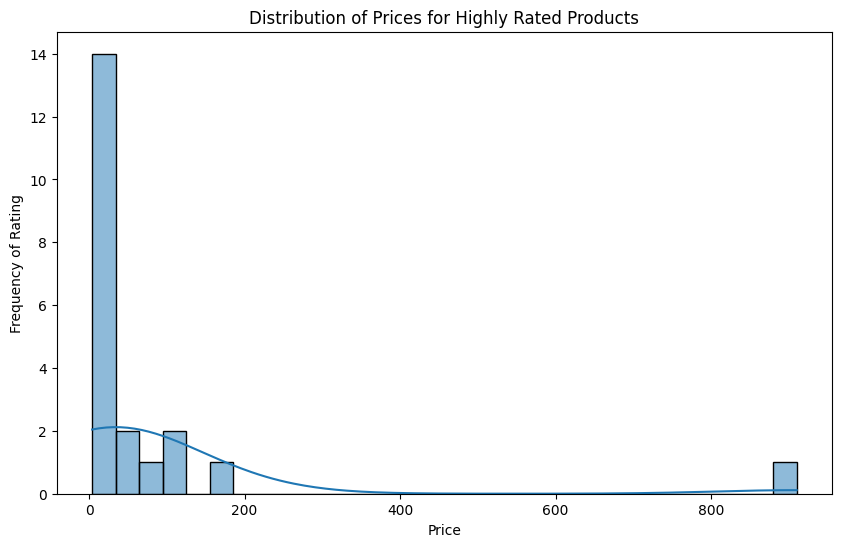

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribution of Prices
plt.figure(figsize=(10, 6))
sns.histplot(
    top_products_df['price'],
    bins=30,
    kde=True
)
plt.title('Distribution of Prices for Highly Rated Products')
plt.xlabel('Price')
plt.ylabel('Frequency of Rating')
plt.show()

## Let's Reflect...
### 💭 Question 6: What trend (if any) do you notice with price and frequency?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [55]:
Question6 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question6) > 0:
    print(f"Question answered! You wrote: {Question6}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: Products of lower price have a lot more frequency of rating.


Question answered! You wrote: Products of lower price have a lot more frequency of rating.


## Part 6.2: Map the Distribution of Prices for Highly Rated Products as a Scatterplot Graph
In this graph, we will want to see if there is a trend for price and ratings, specifically to visualize the distribution of prices for highly rated products (those with an average rating of 4.5 or higher) as a scatterplot, rather than a histogram

#### STEPS TO COMPLETE:
- [ ] Use the `top_products_df` dataframe for the scatterplot graph
- [ ] Plot you graph with the `price` for the x axis and `average_rating` on the y axis

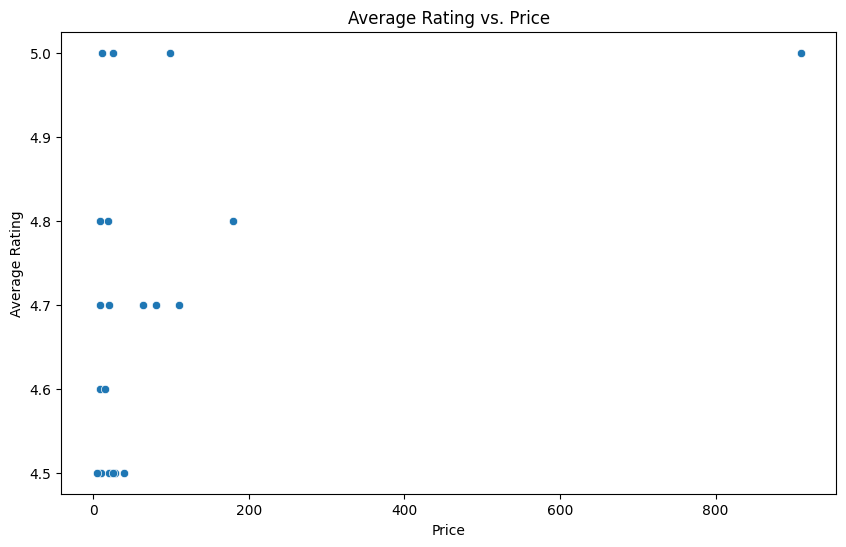

In [56]:
# Average Rating vs. Price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=top_products_df, 
    x='price', 
    y='average_rating'
)
plt.title('Average Rating vs. Price')
plt.xlabel('Price')
plt.ylabel('Average Rating')
plt.show()

## Let's Reflect...
### 💭 Question 7: What trend (if any) do you notice with price and rating?
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `QuestionX`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [57]:
Question7 = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Question7) > 0:
    print(f"Question answered! You wrote: {Question7}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: I couldn't notice too much, maybe I see an abundance of points in the 4.5 rating. 


Question answered! You wrote: I couldn't notice too much, maybe I see an abundance of points in the 4.5 rating. 


## Part 6.3: Display the Distribution of Ratings and Price Together

The "frequency" in this context of a histogram or distribution plot refers to the number of times a particular value or range of values appears in the dataset. In our case, we want to know how often the ratings are coming up related to the price.

For business-facing teams, showing data a couple different ways can be quite helpful, so we will want to visualize these 2 graphs together for maximum impact.

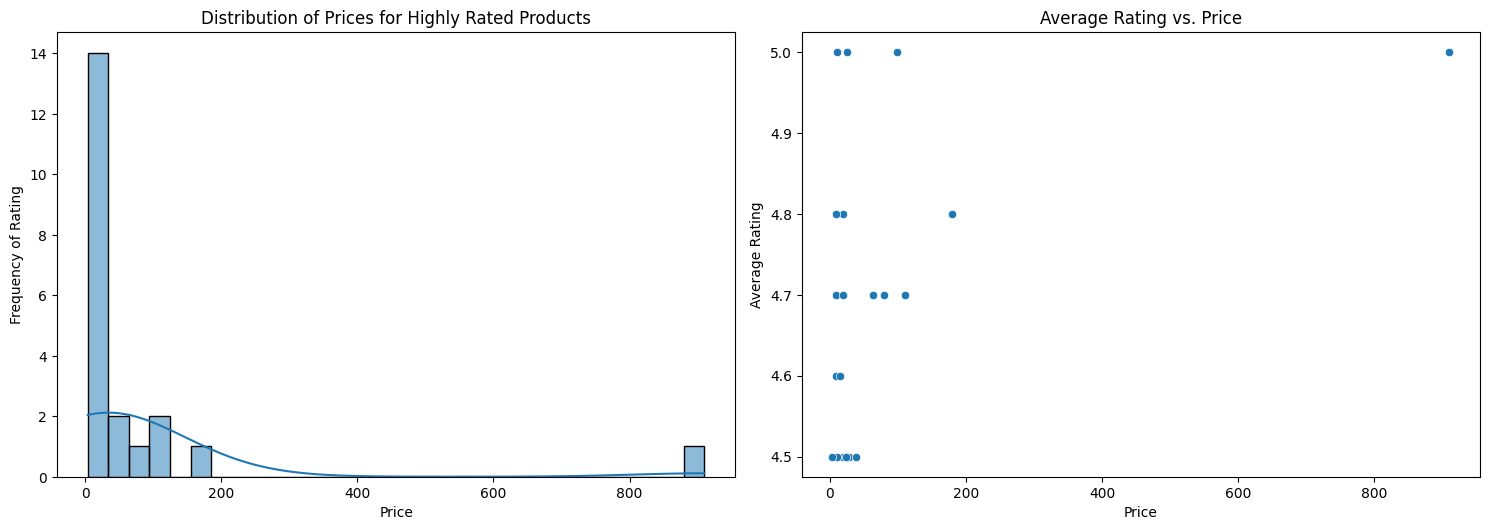

In [58]:
# Create a Dashboard Layout
plt.figure(figsize=(15, 10))

# Subplot 1: Distribution of Prices
plt.subplot(2, 2, 1)
sns.histplot(top_products_df['price'], bins=30, kde=True)
plt.title('Distribution of Prices for Highly Rated Products')
plt.xlabel('Price')
plt.ylabel('Frequency of Rating')

# Subplot 2: Average Rating vs. Price
plt.subplot(2, 2, 2)
sns.scatterplot(data=top_products_df, x='price', y='average_rating')
plt.title('Average Rating vs. Price')
plt.xlabel('Price')
plt.ylabel('Average Rating')

# Feel free to add other visualizations as you like

# Show the Dashboard
plt.tight_layout()
plt.show()

## 6.4: Narrow Down on the Handful of Products that Will be Most Meaningful

To get a better sense of what products the teams will specifically want to double down on, let's use these graphs to create even better outputs.

#### STEPS TO COMPLETE:
- [ ] Specify a cutoff threshold for the results as float data type `4.7`

In [66]:
# Filter the DataFrame to include only products with an average rating of 4.7 or higher
average_rating_cutoff = 4.7
highly_rated_products_df = top_products_df[top_products_df['average_rating'] >= average_rating_cutoff]

# Display the filtered DataFrame
print(highly_rated_products_df)

                                                title  average_rating   price
17  BIPRA U3 2.5 inch USB 3.0 NTFS Portable Extern...             5.0   98.49
16  ANNKE 4K 16CH Security DVR Recorder with Human...             5.0  909.99
97  Monsoon G1/4" to 1/2" ID, 3/4" OD Chain Gun Co...             5.0   25.71
60  MHYALUDO Silicone Print Case Cover for Apple A...             5.0   10.99
24  Polaroid Originals Now Viewfinder i-Type Insta...             4.8  179.99
78  CoBak Case for Kindle Paperwhite - All New PU ...             4.8   18.95
42  Centon Electronics Flash Memory Card (S1-SDHU1...             4.8    8.99
14  Novelty Cute Cartoon USB 2.0 Flash Drive Data ...             4.7    8.98
46  PNY 1TB PRO Elite Class 10 U3 V30 microSDXC Fl...             4.7  109.99
50  JBL FLIP 5 - Waterproof Portable Bluetooth Spe...             4.7   79.90
30  HP Elitebook 8560W New Replacement LCD Screen ...             4.7   63.33
37  Wenlaty Case Compatible with iPad 9th /8th /7t...           

 Count the number of items in the newly cleaned dataset

In [67]:
# Review the new items in cleaned DataFrame
highly_rated_num_items = highly_rated_products_df.shape[0]
print(f"Number of items in the highly rated DataFrame: {highly_rated_num_items}")

Number of items in the highly rated DataFrame: 12


Calculate the percentage of the newly cleaned items with the function you wrote earlier:

In [68]:
part = float(input("Enter the number of items in the highly rated DataFrame: "))
whole = float(input("Enter the number of items in the original top products DataFrame: "))


# Calculate and print the percentage
try:
    result = calculate_percentage(part, whole)
    print(f"{part} is {result:.2f}% of {whole}")
except ValueError as e:
    print(e)

Enter the number of items in the highly rated DataFrame:  12
Enter the number of items in the original top products DataFrame:  21


12.0 is 57.14% of 21.0


Plot the new Histogram distribution with your highly rated DataFrame:

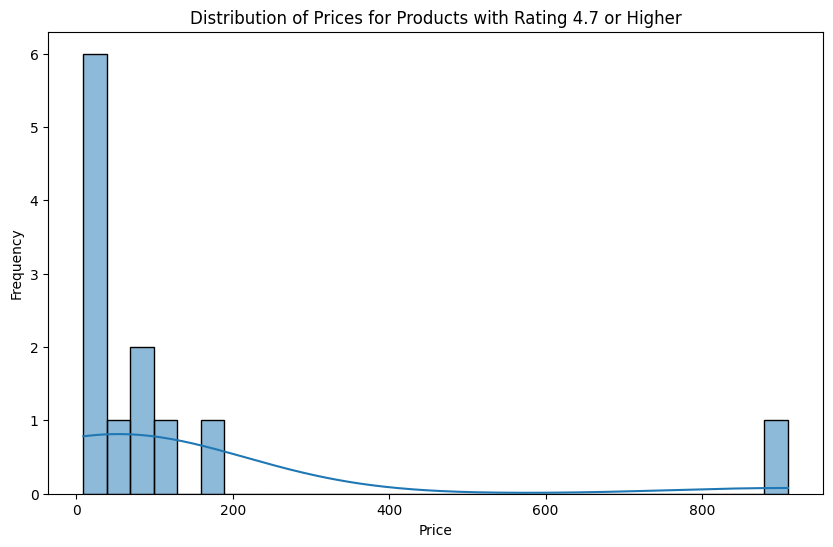

In [69]:
plt.figure(figsize=(10, 6))
sns.histplot(highly_rated_products_df['price'], bins=30, kde=True)
plt.title('Distribution of Prices for Products with Rating 4.7 or Higher')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

Plot the new Scatterplot graph with your new highly rated DataFrame:

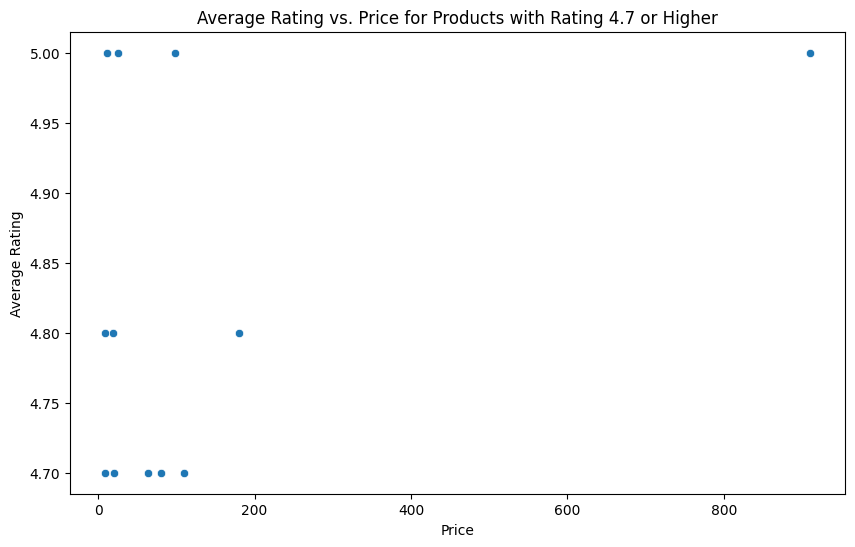

In [62]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=highly_rated_products_df, x='price', y='average_rating')
plt.title('Average Rating vs. Price for Products with Rating 4.7 or Higher')
plt.xlabel('Price')
plt.ylabel('Average Rating')
plt.show()

## 6.5: Create a Dashboard of Your New Findings
The next step will be to create a dashboard for these new results so that you can share this with the Machine Learning, Business, and Executive teams. This section will involve filtering, sorting, and visualizing data, which are key skills covered in the PCEP syllabus.

To accomplish this, we'll:
- Filter the DataFrame: We'll filter the DataFrame to include only products with an average rating of `4.7` or higher.
- Sort the DataFrame: We'll use the `.sort_values` method to sort the DataFrame by average rating in descending order.
- Display the DataFrame: We'll display the sorted DataFrame as a table.
- Create a Scatterplot: We'll create a scatterplot to visualize the relationship between price and average rating for the highly rated products.

#### STEPS TO COMPLETE:
- [ ] Set the `highly_rated_products_df_cutoff` with the desired float threshold value
- [ ] Update the `highly_rated_products_df` to use the `.sort_values` method like you learned in class.
- [ ] Fill in the code to display the new sorted DataFrame
- [ ] Complete the code to create a scatterplot using Seaborn.

Table of Highly Rated Products (Rating 4.7 or Higher, Sorted by Rating):


,title,average_rating,price
17,BIPRA U3 2.5 inch USB 3.0 NTFS Portable Extern...,5.0,98.49
16,ANNKE 4K 16CH Security DVR Recorder with Human...,5.0,909.99
97,"Monsoon G1/4"" to 1/2"" ID, 3/4"" OD Chain Gun Co...",5.0,25.71
60,MHYALUDO Silicone Print Case Cover for Apple A...,5.0,10.99
24,Polaroid Originals Now Viewfinder i-Type Insta...,4.8,179.99
78,CoBak Case for Kindle Paperwhite - All New PU ...,4.8,18.95
42,Centon Electronics Flash Memory Card (S1-SDHU1...,4.8,8.99
14,Novelty Cute Cartoon USB 2.0 Flash Drive Data ...,4.7,8.98
46,PNY 1TB PRO Elite Class 10 U3 V30 microSDXC Fl...,4.7,109.99
50,JBL FLIP 5 - Waterproof Portable Bluetooth Spe...,4.7,79.90


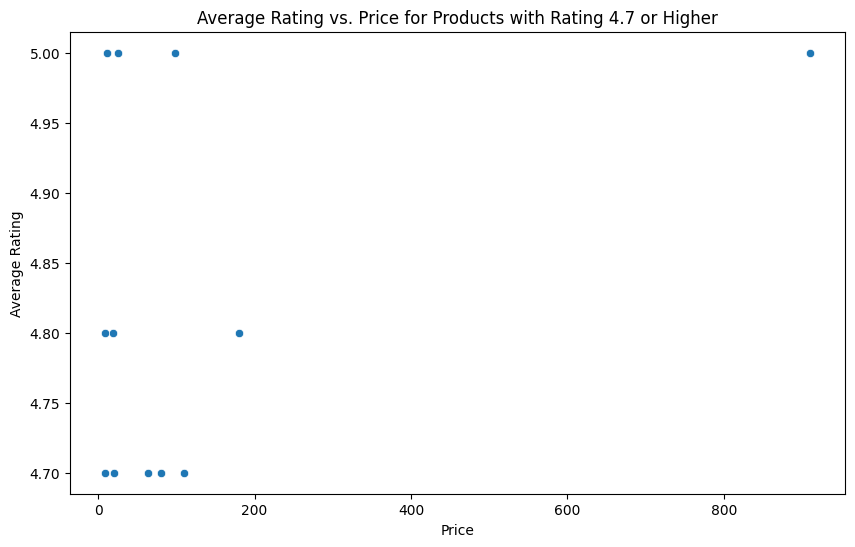

In [63]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

# Filter the DataFrame to include only products with an average rating of 4.7 or higher
highly_rated_products_df_cutoff = 4.7
highly_rated_products_df = top_products_df[top_products_df['average_rating'] >= highly_rated_products_df_cutoff]

# Sort the DataFrame by average_rating in descending order
highly_rated_products_df = highly_rated_products_df.sort_values(by='average_rating', ascending=False)

# Display the sorted DataFrame as a table
print("Table of Highly Rated Products (Rating 4.7 or Higher, Sorted by Rating):")
display(highly_rated_products_df)

# Create the scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=highly_rated_products_df, x='price', y='average_rating')
plt.title('Average Rating vs. Price for Products with Rating 4.7 or Higher')
plt.xlabel('Price')
plt.ylabel('Average Rating')
plt.show()

#### Amazing job!! You did it! 🥳 🎉

# 🎁 Wrap Up

Congratulations, you completed everything that the Machine Learning Team, the Business Team, and the Executive Team at Transformational AI need to get started. You completed this in record time and your manager is excited to offer you a promotion to the Data Science team thanks to all of your hard work! 🥇

To wrap up your excellent work, let's output all of your responses to the questions earlier into a `.txt` file. The code is already written for you, but let's look at what is happening:
- We create an `array` of questions to group all of your data inputs together
- We create a file name as a string called `output_file` where your responses will be written to.
- We write a for loop to iterate over each question, which lives inside of a with statement so that we can write each question and response as a line in the text file
- We use the `print` command to let us know when the file has been created and stored in our notebook.

### 💭 Add your name: Write your first and last name here
Note: By running the following cell, this will create an input field for you to enter your answer and/or code for the questions' defined variable: `Name`. You will see an output of your question by pressing `ENTER` once you are done writing your response in the input field.

In [64]:
Name = str(input("Write Your Answer in the Box and Press Enter:"))

if len(Name) > 0:
    print(f"You added your name: {Name}")
else:
    print("Please answer the question")

Write Your Answer in the Box and Press Enter: Victor Carvalho


You added your name: Victor Carvalho


In [65]:
# Collect all the questions into a list
questions = [Question1, Question2, Question3, Question4, Question5, Question6, Question7]

# Define the file name where your answers will be saved to
output_file = 'user_inputs.txt'

# Write the project details and questions to the output file
with open(output_file, 'w') as file:
    # Write the project title and your name
    file.write("Transformational AI: Analyzing Ecommerce Large Datasets for Machine Learning\n")
    file.write(f"Completed by: {Name}\n")
    file.write("—————————————-\n\n")

    # Write each question and its response on subsequent line
    for i, question in enumerate(questions, start=1):
        file.write(f"Question {i}: {question}\n")

print(f"All questions have been written to {output_file}")

All questions have been written to user_inputs.txt


## 📁 Be Sure to Download Your Great Work:
You should see these in the file directory on the left:
- [ ] This Jupyter Notebook with your cell outputs included
- [ ] Your `user_inputs.txt` file with your answers to all reflection questions
- [ ] Your `top_products.csv` dataset
- [ ] Your `top_products.parquet` dataset